# 从一次计算到工具执行

第一课教师演示 · 中文 · 2026-11-04

先“运行全部”，再修改半径重跑。前半段真实执行计算、绘图和文件读取；后半段用**教师预写的请求模拟模型输出**，没有联网调用大模型。学生不需要自行编写这些程序。

教师准备见同目录 README.md。依赖 Python 3、Jupyter/IPython 和 matplotlib。

## 1. 算一个圆的面积

半径单位为 mm，面积单位为 mm²。先预测半径从 2 增大到 3 后面积如何变化。


In [1]:
import math

radius_mm = 2.0
area_mm2 = math.pi * radius_mm ** 2
print(f"半径：{radius_mm:g} mm；面积：{area_mm2:.2f} mm²")


半径：2 mm；面积：12.57 mm²


## 2. 一键画出半径与面积的关系

横轴为半径（mm），纵轴为面积（mm²）。圆点对应上一格的半径。修改上一格的半径后，再依次运行两格。

曲线是几何公式的结果，不是实验测量数据。图中使用英文标签，便于在未安装中文字体的电脑上显示。


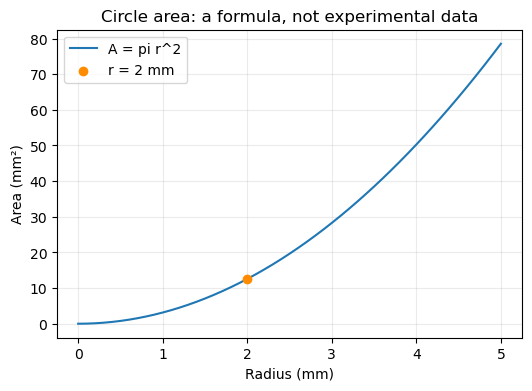

In [2]:
import matplotlib.pyplot as plt

radii_mm = [i / 10 for i in range(51)]
areas_mm2 = [math.pi * r ** 2 for r in radii_mm]
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(radii_mm, areas_mm2, label="A = pi r^2")
ax.scatter([radius_mm], [area_mm2], color="darkorange", zorder=3,
           label=f"r = {radius_mm:g} mm")
ax.set(xlabel="Radius (mm)", ylabel="Area (mm²)",
       title="Circle area: a formula, not experimental data")
ax.grid(alpha=0.25)
ax.legend()
plt.show()


## 3. 从文件字节读回文字

[课堂样例 `sample.zh.txt`](../../../演示/sample.zh.txt) 使用 UTF-8 保存中文。先读取文件第一行的原始字节，把每个字节打印成 8 位二进制数；再用 UTF-8 解码，观察它们对应的文字。最后把开头两个汉字重新编码，核对每个汉字对应的字节。

In [3]:
from pathlib import Path

candidates = [Path("../../../演示/sample.zh.txt"), Path("演示/sample.zh.txt"),
              Path("lesson01/演示/sample.zh.txt")]
file_path = next((path for path in candidates if path.is_file()), None)
if file_path is None:
    raise FileNotFoundError("请从课程根目录或 lesson01/演示目录运行 Notebook")

raw_bytes = file_path.read_bytes()
first_line_bytes = raw_bytes.splitlines()[0]
print("文件第一行的字节（二进制，每组 8 位）：")
for offset in range(0, len(first_line_bytes), 8):
    print(" ".join(f"{byte:08b}" for byte in first_line_bytes[offset:offset + 8]))

text = first_line_bytes.decode("utf-8")
print("UTF-8 解码后的文字：", text)
for character in text[:2]:
    bits = " ".join(f"{byte:08b}" for byte in character.encode("utf-8"))
    print(f"{bits} → {character}")

文件第一行的字节（二进制，每组 8 位）：
11100110 10100000 10110111 11100101 10010011 10000001 00100000 01001101
00101101 00110000 00110010 00100000 11100110 10011000 10101111 11100100
10111000 10000000 11100100 10111000 10101010 11101000 10011001 10011010
11100110 10011110 10000100 11100111 10100100 10111010 11100100 10111110
10001011 11100011 10000000 10000010
UTF-8 解码后的文字： 样品 M-02 是一个虚构示例。
11100110 10100000 10110111 → 样
11100101 10010011 10000001 → 品


## 4. 先准备一个可被调用的工具

`circle_area` 是工具名，`radius_mm` 是参数名。下面的代码负责实际计算，也检查参数是不是有限的非负数。这不是模型自己创造出来的工具，而是教师预先注册的函数。


In [4]:
def circle_area(radius_mm):
    if isinstance(radius_mm, bool) or not isinstance(radius_mm, (int, float)):
        raise ValueError("半径必须是数值")
    if not math.isfinite(radius_mm) or radius_mm < 0:
        raise ValueError("半径必须是有限的非负数")
    return {"area_mm2": math.pi * radius_mm ** 2}

print("可用工具：circle_area；参数：radius_mm，单位 mm")


可用工具：circle_area；参数：radius_mm，单位 mm


## 5. 模拟模型提出调用，再由外围程序执行

以下 JSON 是**教师预写的模拟请求**，不是某家 API 的完整报文。真实系统中，Harness 会把工具说明提供给模型，再按对应协议接收调用消息。

这里只允许执行已经登记的工具，不把任意文字直接当作代码运行。


In [5]:
import json

request_text = '{"name": "circle_area", "arguments": {"radius_mm": 2.0}}'

def dispatch(request_text):
    request = json.loads(request_text)
    if not isinstance(request, dict) or set(request) != {"name", "arguments"}:
        raise ValueError("请求需要 name 和 arguments")
    if request["name"] != "circle_area":
        raise ValueError("没有注册这个工具")
    arguments = request["arguments"]
    if not isinstance(arguments, dict) or set(arguments) != {"radius_mm"}:
        raise ValueError("参数需要 radius_mm")
    return circle_area(**arguments)

result = dispatch(request_text)
print("模拟请求：", request_text)
print("真实工具结果：", json.dumps(result, ensure_ascii=False))
print(f"教师预写的回答模板：面积约为 {result['area_mm2']:.2f} mm²。")


模拟请求： {"name": "circle_area", "arguments": {"radius_mm": 2.0}}
真实工具结果： {"area_mm2": 12.566370614359172}
教师预写的回答模板：面积约为 12.57 mm²。


## 6. 格式正确也不代表参数合理

下面的请求仍是有效 JSON，但半径为负数。观察调度程序与工具如何返回错误。真实系统可以把错误交回模型，让它补充信息或修改请求；本演示没有模拟自主重试。


In [6]:
bad_request = '{"name": "circle_area", "arguments": {"radius_mm": -2.0}}'
try:
    dispatch(bad_request)
except ValueError as error:
    print("工具拒绝请求：", error)


工具拒绝请求： 半径必须是有限的非负数


## 7. 对照与核验

- 直接计算和工具调用采用同一个圆面积公式。
- 半径 2 mm 的面积应为 4π mm²，约 12.57 mm²。
- 半径 3 mm 的面积是 9π mm²，约 28.27 mm²；它是前者的 2.25 倍。
- JSON 是请求的表达方式；实际运算发生在 `circle_area` 函数执行时。
- 计算输出与最后一句文字回答是不同步骤。

实际 Agent 还需要组织上下文、连接模型、管理执行权限及记录。这个小程序只演示其中的请求检查与工具分发。
